# The ≈860 d signal and injection-recovery with the analytic Baluev FAP



In [50]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.optimize import brentq
from scipy.special import gammaln
import cmasher as cmr
from astropy.timeseries import LombScargle

from sunsim import local_path, observations as obs
from sunsim.residuals import ResidualAnalysis

plt.rcParams.update({
    "figure.figsize": (15, 9), "font.size": 15, "axes.labelsize": 15, "axes.titlesize": 15, "xtick.labelsize": 15,
    "ytick.labelsize": 15, "legend.fontsize": 13, "axes.linewidth": 0.5, "xtick.direction": "in",
    "ytick.direction": "in", "xtick.top": True, "ytick.right": True, "lines.linewidth": 1.5, "lines.markersize": 3,
})

SIM_RV = os.path.join(local_path('personal_data'), 'rv-15.txt')
ORIGIN = '2015-07-18'                # t = 0 of the simulation
FIRST, LAST = '2015-07-18', '2024-01-28'
FIGURES = None                       # folder where the PDFs are saved, e.g. "/Users/sophiestucki/Documents/rv_opt/figures/final/"; None: not saved

FAP = 1e-3                           # detection threshold (analytic Baluev FAP)
PERIOD_TOL = 0.1                     # recovered period within 10 % of the injected one
P_SCALE = 'list'                     # injected periods [whole days] containing 365 d: 'list', 'linear' or 'log'
PERIODS_LIST = [5, 10, 20, 50, 100, 150, 200, 300, 365, 450, 575]   # list: none within 10 % of a residual peak
P_MIN, P_MAX = 5, 550                # [d] shortest and longest injected period
P_STEP = 40                          # linear: step [d] (5 + n P_STEP = 365)
P_SUB = 2                            # log: P_SUB steps between 365 d and P_MAX (factor (P_MAX / 365) ** (1 / P_SUB) = 1.23)
EXCL_TOL = 0.10                      # injected periods kept only further than EXCL_TOL (relative) from a residual peak
EXCL_RUNS = 'ABC'                    # runs whose significant residual peaks are avoided
if P_SCALE == 'list':
    PERIODS_GRID = np.array(PERIODS_LIST, dtype=float)
elif P_SCALE == 'linear':
    PERIODS_GRID = np.arange(P_MIN, P_MAX + 1, P_STEP, dtype=float)
else:
    PERIODS_GRID = np.unique(np.round(365 * (P_MAX / 365) ** (np.arange(-100, P_SUB + 1) / P_SUB)))
    PERIODS_GRID = PERIODS_GRID[(PERIODS_GRID >= P_MIN) & (PERIODS_GRID <= P_MAX)]
AMPLITUDES = np.linspace(0.1, 0.5, 21)   # injected semi-amplitudes [m/s]
N_PHASES = 100                       # times of transit per (P, K)
LONG = (500, 1500)                   # [d] range of the long-period peaks
P860_RANGE = (750, 1000)             # [d] range where the ≈860 d peak is searched
YEAR = 365.25


def save(fig, name):
    if FIGURES:
        fig.savefig(os.path.join(FIGURES, name + '.pdf'), bbox_inches='tight', dpi=300)

## Data

In [51]:
t_s, rv_s = np.loadtxt(SIM_RV).T
window = (t_s >= obs.jd_of_date(FIRST) - obs.jd_of_date(ORIGIN)) & (t_s < obs.jd_of_date(LAST) - obs.jd_of_date(ORIGIN) + 1)
t_s, rv_s = t_s[window], rv_s[window]
harps = obs.load_harpsn(local_path('harpsn_sun'), ORIGIN, end=LAST, t_start=FIRST)
cuts = obs.load_interventions(local_path('harpsn_interventions'), ORIGIN)
rv = obs.compare_rv(harps, t_s, rv_s, interventions=cuts)

order = np.argsort(rv['t'], kind='stable')
T = np.asarray(rv['t'], dtype=float)[order]
G = np.asarray(rv['period'])[order]
Y_OBS = np.asarray(rv['obs'], dtype=float)[order]          # HARPS-N, one median removed
Y_SIM = np.asarray(rv['sim'], dtype=float)[order]          # SunSim on the same days
Y_RES = np.asarray(rv['res'], dtype=float)[order]          # HARPS-N - SunSim, median of every interval removed
Y_OBS_OFF = Y_OBS.copy()                                   # HARPS-N, median of every interval removed
for g in np.unique(G):
    Y_OBS_OFF[G == g] -= np.median(Y_OBS_OFF[G == g])
print('%d days, %d intervals, %.0f d' % (len(T), len(np.unique(G)), np.ptp(T)))

1984 days, 21 intervals, 3101 d


## Model: GLS with nuisance terms and the Baluev FAP

In [52]:
def baluev_fap(z, N, d_H, fmax, t):
    # Baluev (2008) eq. 6 (astropy method='baluev', normalisation 'standard'), base model of d_H linear parameters,
    # equal weights. z: power (ZK); fmax: highest frequency searched [1/d].
    z = np.clip(np.asarray(z, dtype=np.float64), 0, 1)
    NH, NK = N - d_H, N - d_H - 2
    fap1 = (1 - z) ** (0.5 * NK)
    gamma = np.sqrt(2 / NH) * np.exp(gammaln(NH / 2) - gammaln((NH - 1) / 2))
    W = fmax * np.sqrt(4 * np.pi * np.var(t))
    tau = gamma * W * (1 - z) ** (0.5 * (NK - 1)) * np.sqrt(0.5 * NH * z)
    out = -np.expm1(-tau) + fap1 * np.exp(-tau)
    return out if out.ndim else float(out)


class Baluev(ResidualAnalysis):
    # GLS where a constant (or one offset per interval, offsets=True) and a sinusoid at every period of `fixed`
    # [d] are fitted together with the trial sinusoid at every frequency (least squares, equal weights); power =
    # chi2 reduction relative to the fit without the trial sinusoid; FAP: Baluev (2008) with d_H = number of these
    # nuisance parameters. offsets=False and fixed=(): the GLS of ResidualAnalysis.

    def __init__(self, t, y, offsets=False, fixed=(), **kw):
        super().__init__(t, y, **kw)
        if offsets:
            g = np.unique(self.groups, return_inverse=True)[1]
            X = np.zeros((self.N, int(g.max()) + 1))
            X[np.arange(self.N), g] = 1
        else:
            X = np.ones((self.N, 1))
        self.fixed = tuple(fixed)
        self.X = np.hstack([X] + [np.column_stack([np.cos(2 * np.pi * self.th / P), np.sin(2 * np.pi * self.th / P)])
                                  for P in self.fixed])
        self.d_H = self.X.shape[1]
        self._WX = self.X * self.w[:, None]
        self._Hinv = np.linalg.inv(self.X.T @ self._WX)
        nf = len(self.freq)
        CC, SS, CS = np.empty(nf), np.empty(nf), np.empty(nf)
        for sl, cos, sin in self._trig():
            Ac, As = cos @ self._WX, sin @ self._WX
            CC[sl] = (cos * cos) @ self.w - np.einsum('fq,qr,fr->f', Ac, self._Hinv, Ac)
            SS[sl] = (sin * sin) @ self.w - np.einsum('fq,qr,fr->f', As, self._Hinv, As)
            CS[sl] = (cos * sin) @ self.w - np.einsum('fq,qr,fr->f', Ac, self._Hinv, As)
        self._CC, self._SS, self._CS = CC, SS, CS
        self._D = CC * SS - CS ** 2
        self._C, self._S = np.zeros(nf), np.zeros(nf)

    def center(self, y):
        # y minus its least-squares fit by the nuisance terms
        return y - self.X @ (self._Hinv @ (self._WX.T @ y))

    def _gls(self, y):
        y = np.asarray(y, dtype=np.float64)
        one = y.ndim == 1
        y = y[:, None] if one else y
        wy = self.center(y)
        YY = self.w @ wy ** 2
        wy = wy * self.w[:, None]
        YC, YS = np.empty((len(self.freq), y.shape[1])), np.empty((len(self.freq), y.shape[1]))
        for sl, cos, sin in self._trig():
            YC[sl], YS[sl] = cos @ wy, sin @ wy
        CC, SS, CS, D = (v[:, None] for v in (self._CC, self._SS, self._CS, self._D))
        a = (YC * SS - YS * CS) / D
        b = (YS * CC - YC * CS) / D
        power = (SS * YC * YC + CC * YS * YS - 2 * CS * YC * YS) / (YY * D)
        out = (power, a, b, np.zeros_like(a))
        return tuple(v[:, 0] for v in out) if one else out

    def fap(self, power):
        return baluev_fap(power, self.N, self.d_H, self.freq[-1], self.t)

    def power_level(self, fap):
        return brentq(lambda z: np.log(max(self.fap(z), 1e-300)) - np.log(fap), 1e-9, 1 - 1e-9)


def spectrum(ra, y=None):
    # power, semi-amplitude and period of every frequency of the GLS of y (default ra.y)
    power, a, b, _ = ra._gls(ra.y if y is None else y)
    return {'P': 1 / ra.freq, 'power': power, 'amp': np.hypot(a, b)}


def peak_in(ra, sp, pmin=0, pmax=np.inf):
    # highest peak of sp with a period in [pmin, pmax]: period, semi-amplitude, power, Baluev FAP
    m = (sp['P'] >= pmin) & (sp['P'] <= pmax)
    k = np.flatnonzero(m)[np.argmax(sp['power'][m])]
    return {'P': sp['P'][k], 'K': sp['amp'][k], 'power': sp['power'][k], 'FAP': ra.fap(sp['power'][k])}


def local_peaks(ra, sp, fap=FAP):
    # every local maximum of sp with Baluev FAP <= fap, from the strongest
    p = sp['power']
    k = np.flatnonzero((p[1:-1] > p[:-2]) & (p[1:-1] >= p[2:])) + 1
    k = k[p[k] >= ra.power_level(fap)]
    k = k[np.argsort(-p[k])]
    return pd.DataFrame({'P [d]': sp['P'][k], 'K [m/s]': sp['amp'][k], 'power': p[k], 'FAP': ra.fap(p[k])})

### Check against astropy (model with a constant only, d_H = 1)

In [53]:
ra = Baluev(T, Y_RES)
sp = spectrum(ra)
ls = LombScargle(T, Y_RES)                        # fit_mean, center_data, normalisation 'standard'
p_astropy = ls.power(ra.freq, method='cython')    # exact (the default 'fast' method approximates)
print('power: max |ours - astropy| = %.1e' % np.max(np.abs(sp['power'] - p_astropy)))
faps = np.array([1e-1, 1e-2, 1e-3, 1e-4, 1e-6])
z_astropy = ls.false_alarm_level(faps, method='baluev', maximum_frequency=ra.freq[-1])
fap_back = ls.false_alarm_probability(z_astropy, method='baluev', maximum_frequency=ra.freq[-1])
for f, z, fb in zip(faps, z_astropy, fap_back):
    print('FAP %.0e: power astropy %.6f, ours %.6f; FAP at that power: astropy %.4e, ours %.4e'
          % (f, z, ra.power_level(f), fb, ra.fap(z)))
print('power at FAP = %g: Baluev %.5f, Zechmeister & Kuerster formula (ResidualAnalysis) %.5f'
      % (FAP, ra.power_level(FAP), ResidualAnalysis.power_level(ra, FAP)))

power: max |ours - astropy| = 1.9e-15
FAP 1e-01: power astropy 0.010407, ours 0.010407; FAP at that power: astropy 1.0000e-01, ours 1.0000e-01
FAP 1e-02: power astropy 0.012859, ours 0.012859; FAP at that power: astropy 1.0000e-02, ours 1.0000e-02
FAP 1e-03: power astropy 0.015241, ours 0.015241; FAP at that power: astropy 1.0000e-03, ours 1.0000e-03
FAP 1e-04: power astropy 0.017601, ours 0.017601; FAP at that power: astropy 1.0000e-04, ours 1.0000e-04
FAP 1e-06: power astropy 0.022276, ours 0.022276; FAP at that power: astropy 1.0000e-06, ours 1.0000e-06
power at FAP = 0.001: Baluev 0.01524, Zechmeister & Kuerster formula (ResidualAnalysis) 0.01384


## 1. HARPS-N alone: the ≈860 d signal without and with the offsets

GLS (constant + sinusoid) of the HARPS-N RVs on the days of the comparison, (a) as they are, (b) with the median of
every intervention interval removed first (the 21 offsets), and, for comparison, (c) with the 21 offsets fitted jointly
with the trial sinusoid at every frequency (as in `peak_860d`, d_H = 21). Highest peak in 500–1500 d and its Baluev
FAP.

,highest peak [d],K [m/s],FAP,500-1500 d: peak [d],500-1500 d: K [m/s],500-1500 d: FAP
series,,,,,,
"HARPS-N, no offset",1.03e+04,13,0,1.35e+03,1.17,2.11e-53
"HARPS-N, 21 offsets removed",26.4,0.492,4.82e-24,738,0.257,5.31e-05
"HARPS-N, 21 offsets fitted jointly",26.4,0.497,2.38e-24,1.48e+03,1.28,4.68e-19


local peaks with Baluev FAP <= 0.001:


K [m/s]  power      FAP
series                             P [d]                           
HARPS-N, no offset                 10336.7       13  0.648        0
                                   1348.3      1.17  0.124 2.11e-53
                                   1000.3     0.882 0.0632 6.61e-25
                                   704.8      0.775 0.0465 2.47e-17
                                   408.0      0.616  0.032 6.11e-11
                                   563.8      0.594 0.0314  1.1e-10
                                   26.4       0.516 0.0231 4.22e-07
                                   484.5      0.444  0.017 0.000183
                                   26.2       0.427 0.0158 0.000594
HARPS-N, 21 offsets removed        26.4       0.492 0.0614 4.82e-24
                                   26.1       0.363 0.0332 1.81e-11
                                   13.3        0.32 0.0261 2.28e-08
                                   14.3       0.317 0.0247 8.68e-08
                                   25.9       0.281 0.0195 1.49e-05
                                   31.6       0.273 0.0189 2.74e-05
                                   738.3      0.257 0.0182 5.31e-05
                                   27.7        0.27 0.0182 5.56e-05
                                   563.8      0.264  0.018 6.72e-05
                                   14.2       0.268  0.018 7.04e-05
                                   25.1       0.263  0.017 0.000178
                                   25.3       0.256 0.0162 0.000386
                                   492.2      0.257 0.0161 0.000454
                                   14.4       0.251 0.0159 0.000506
                                   1069.3     0.245 0.0158 0.000596
                                   13.4        0.25 0.0157 0.000653
                                   130.8      0.249 0.0155   0.0008
HARPS-N, 21 offsets fitted jointly 26.4       0.497 0.0626 2.38e-24
                                   4430.0      3.65 0.0609 1.51e-23
                                   1632.1      1.38 0.0568 9.92e-22
                                   469.8      0.715 0.0471 2.06e-17
                                   1033.7     0.856 0.0471 2.11e-17
                                   738.3      0.722 0.0434 8.67e-16
                                   574.3      0.713 0.0417 4.95e-15
                                   26.1       0.364 0.0334 2.12e-11
                                   13.3       0.323 0.0266 1.74e-08
                                   14.3       0.314 0.0244 1.58e-07
                                   25.9       0.284   0.02 1.19e-05
                                   424.8      0.432 0.0192 2.42e-05
                                   14.2       0.272 0.0185 4.99e-05
                                   387.6      0.412 0.0183 5.75e-05
                                   31.6       0.269 0.0183 5.76e-05
                                   27.7       0.268 0.0179 8.54e-05
                                   25.1       0.267 0.0176  0.00012
                                   130.8      0.268 0.0171   0.0002
                                   152.8      0.277 0.0167 0.000272
                                   25.3       0.258 0.0165 0.000352
                                   13.4       0.251 0.0158 0.000664

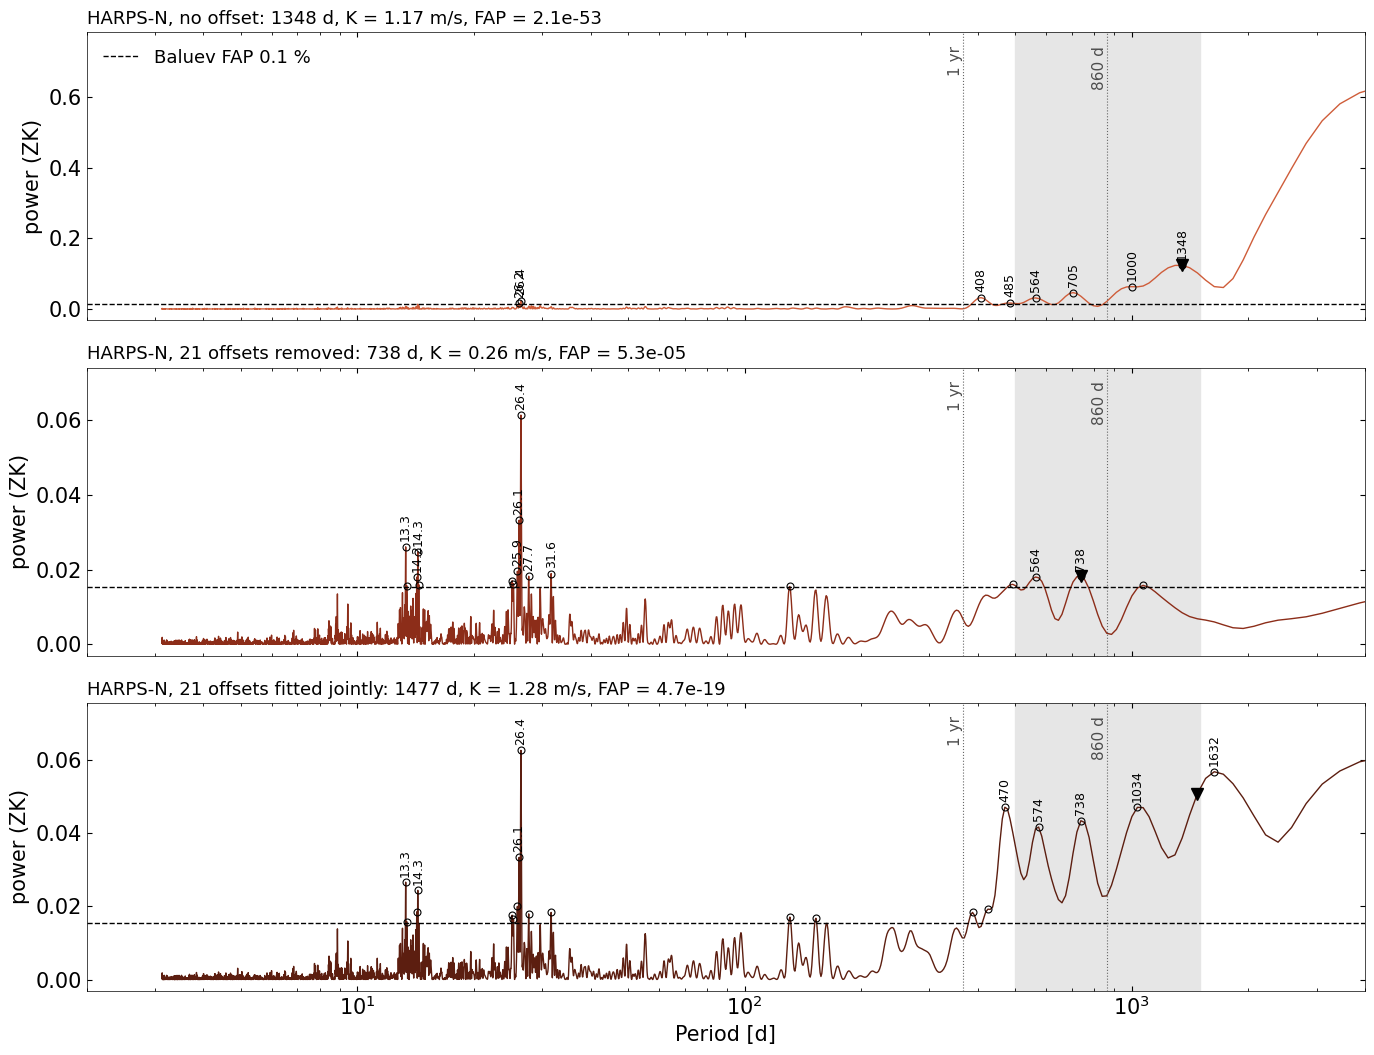

In [54]:
Y_SIM_OFF = Y_SIM.copy()                                   # SunSim, median of every interval removed
for g in np.unique(G):
    Y_SIM_OFF[G == g] -= np.median(Y_SIM_OFF[G == g])
CASES = {'obs': ('HARPS-N, no offset', Y_OBS), 'obs_off': ('HARPS-N, 21 offsets removed', Y_OBS_OFF),
         'res': ('HARPS-N $-$ SunSim, 21 offsets removed', Y_RES), 'sim_off': ('SunSim, 21 offsets removed', Y_SIM_OFF)}
models = {k: Baluev(T, y, name=label) for k, (label, y) in CASES.items()}
models['obs_joint'] = Baluev(T, Y_OBS, offsets=True, groups=G, name='HARPS-N, 21 offsets fitted jointly')
models['res_joint'] = Baluev(T, Y_RES, offsets=True, groups=G, name='HARPS-N $-$ SunSim, 21 offsets fitted jointly')
spectra = {k: spectrum(ra) for k, ra in models.items()}


def peak_table(keys):
    rows = []
    for k in keys:
        ra, sp = models[k], spectra[k]
        top, lng = peak_in(ra, sp), peak_in(ra, sp, *LONG)
        rows.append({'series': ra.name.replace('$-$', '-'), 'highest peak [d]': top['P'], 'K [m/s]': top['K'],
                     'FAP': top['FAP'], '%d-%d d: peak [d]' % LONG: lng['P'], '%d-%d d: K [m/s]' % LONG: lng['K'],
                     '%d-%d d: FAP' % LONG: lng['FAP']})
    return pd.DataFrame(rows).set_index('series')


pd.options.display.float_format = '{:.3g}'.format
display(peak_table(('obs', 'obs_off', 'obs_joint')))


N_LABEL = 10                         # periods written on the plot: the N_LABEL strongest peaks above the FAP


def plot_periodograms(items, marks=(), title=''):
    # items: list of (Baluev model, spectrum, colour); a panel each. Every local peak above the FAP level is marked
    # (the N_LABEL strongest labelled with their period) and all of them are listed in a table.
    tables = []
    fig, axes = plt.subplots(len(items), 1, figsize=(14, 3.6 * len(items)), sharex=True, squeeze=False)
    for ax, (ra, sp, colour) in zip(axes[:, 0], items):
        ax.plot(sp['P'], sp['power'], color=colour, lw=1)
        ax.axhline(ra.power_level(FAP), color='k', lw=1, ls='--', label='Baluev FAP %g %%' % (100 * FAP))
        ax.axvspan(*LONG, color='0.9', zorder=0)
        for name, p in (('1 yr', YEAR), *marks):
            ax.axvline(p, color='0.4', lw=0.8, ls=':')
            ax.text(p, 0.97, name + ' ', transform=ax.get_xaxis_transform(), fontsize=11, va='top', ha='right',
                    rotation=90, color='0.3')
        pk = local_peaks(ra, sp)
        ax.plot(pk['P [d]'], pk['power'], 'o', mfc='none', mec='k', ms=5, mew=0.8)
        for P, p in zip(pk['P [d]'][:N_LABEL], pk['power'][:N_LABEL]):
            ax.annotate('%.1f' % P if P < 100 else '%.0f' % P, (P, p), xytext=(0, 4), textcoords='offset points',
                        fontsize=9, rotation=90, ha='center', va='bottom')
        tables.append(pk.assign(**{'series': ra.name.replace('$-$', '-'), 'P [d]': pk['P [d]'].map('{:.1f}'.format)}))
        lng = peak_in(ra, sp, *LONG)
        ax.plot(lng['P'], lng['power'], 'v', color='k', ms=8)
        ax.set_ylim(top=ax.get_ylim()[1] * 1.15)
        ax.set_title('%s: %.0f d, K = %.2f m/s, FAP = %.1e' % (ra.name, lng['P'], lng['K'], lng['FAP']), loc='left',
                     fontsize=13)
        ax.set_ylabel('power (ZK)')
        ax.set_xscale('log')
        ax.set_xlim(2, 4000)
    axes[0, 0].legend(frameon=False, loc='upper left')
    axes[-1, 0].set_xlabel('Period [d]')
    fig.tight_layout()
    print('local peaks with Baluev FAP <= %g:' % FAP)
    display(pd.concat(tables).set_index(['series', 'P [d]']))
    return fig


fig = plot_periodograms([(models[k], spectra[k], c) for k, c in (('obs', '#cf5d3a'), ('obs_off', '#8c2d19'),
                                                                    ('obs_joint', '#5c1e10'))], marks=(('860 d', 860),))
save(fig, 'gls_harpsn_860')
plt.show()

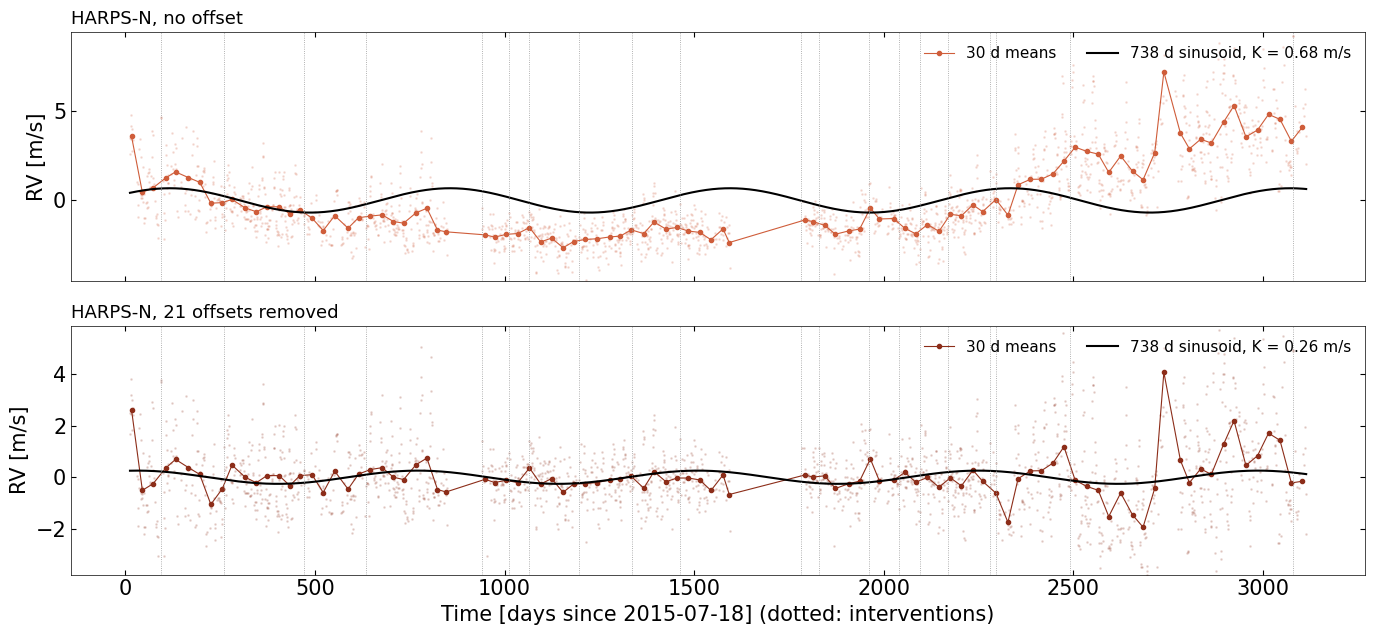

In [55]:
def sine_fit(t, y, P, groups=None):
    # least squares: a constant (or one offset per group) + sinusoid at P; returns the offsets removed from y,
    # the sinusoid on a fine grid and its semi-amplitude
    g = np.zeros(len(t), int) if groups is None else np.unique(groups, return_inverse=True)[1]
    X = np.zeros((len(t), g.max() + 1))
    X[np.arange(len(t)), g] = 1
    th = t - t[0]
    X = np.hstack([X, np.column_stack([np.cos(2 * np.pi * th / P), np.sin(2 * np.pi * th / P)])])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    tt = np.linspace(t[0], t[-1], 3000)
    model = beta[-2] * np.cos(2 * np.pi * (tt - t[0]) / P) + beta[-1] * np.sin(2 * np.pi * (tt - t[0]) / P)
    return y - beta[g], (tt, model), np.hypot(beta[-2], beta[-1])


def plot_series(keys, colours, P):
    # 30-day means of every series (constant removed) and the sinusoid at P fitted with a constant
    fig, axes = plt.subplots(len(keys), 1, figsize=(14, 3.3 * len(keys)), sharex=True, squeeze=False)
    bins = np.floor(T / 30)
    starts = [T[G == g][0] for g in np.unique(G)[1:]]
    for ax, k, c in zip(axes[:, 0], keys, colours):
        y, (tt, model), amp = sine_fit(T, CASES[k][1], P)
        ax.plot(T, y, '.', color=c, alpha=0.15, ms=2)
        ax.plot(pd.Series(T).groupby(bins).mean(), pd.Series(y).groupby(bins).mean(), 'o-', color=c, ms=3, lw=0.8,
                label='30 d means')
        ax.plot(tt, model, color='k', lw=1.5, label='%.0f d sinusoid, K = %.2f m/s' % (P, amp))
        for s in starts:
            ax.axvline(s, color='0.6', lw=0.6, ls=':')
        ax.set_ylim(np.percentile(y, [1, 99]) * 1.3)
        ax.set_ylabel('RV [m/s]')
        ax.set_title(CASES[k][0], loc='left', fontsize=13)
        ax.legend(frameon=False, fontsize=11, loc='upper right', ncol=2)
    axes[-1, 0].set_xlabel('Time [days since %s] (dotted: interventions)' % ORIGIN)
    fig.tight_layout()
    return fig


P_OBS = peak_in(models['obs_off'], spectra['obs_off'], *LONG)['P']
fig = plot_series(('obs', 'obs_off'), ('#cf5d3a', '#8c2d19'), P_OBS)
plt.show()

**Conclusion (HARPS-N alone).** There is **no ≈860 d signal in HARPS-N alone**, whatever the treatment of the offsets:

* **No offset:** the long periods are dominated by the solar cycle. The power rises steadily beyond ≈2000 d, and in
  500–1500 d the highest point (1348 d, K = 1.2 m/s) lies on the flank of the cycle. 860 d falls in a minimum.
* **21 offsets removed:** removing the median of intervals a few months long acts as a high-pass filter, so the long
  periods are strongly reduced. The highest peak in 500–1500 d is 738 d (K = 0.26 m/s, Baluev FAP 5 × 10⁻⁵), next to
  peaks at ≈560 and ≈1050 d. 860 d again falls in a minimum.
* **21 offsets fitted jointly:** every period above ≈400 d is "significant" (free offsets + the cycle). The highest
  is 1477 d, and 860 d is once more a minimum.

## 2. HARPS-N − SunSim (offsets removed)

The residuals `rv['res']` (median of every interval removed), and for comparison with the 21 offsets fitted jointly.
P₈₆₀: highest peak of the residuals in 750–1000 d; P_long: highest peak in 500–1500 d. Then the GLS with the P₈₆₀
sinusoid fitted jointly (model B) and with the P_long sinusoid (model C), i.e. what is left. Last table: the
semi-amplitude of a sinusoid at P₈₆₀ and P_long in HARPS-N and SunSim (both with the 21 offsets removed) and in the
residuals (least squares with a constant), to see where it comes from.

P_860 = 838.1 d, P_long = 632.9 d; 1/P_long - 1/P_860 = 1/2584 d (1/T = 1/3101 d)


,highest peak [d],K [m/s],FAP,500-1500 d: peak [d],500-1500 d: K [m/s],500-1500 d: FAP
series,,,,,,
"HARPS-N - SunSim, 21 offsets removed",633,0.163,1.52e-06,633,0.163,1.52e-06
"HARPS-N - SunSim, 21 offsets fitted jointly",861,0.595,1.1e-23,861,0.595,1.1e-23
"HARPS-N - SunSim, 838 d fitted",28.5,0.147,7.74e-05,500,0.142,0.000213
"HARPS-N - SunSim, 633 d fitted",28.5,0.147,7.72e-05,517,0.138,0.000503


significant peaks (Baluev FAP <= 0.001) of the residuals:


,P [d],K [m/s],power,FAP
0,633,0.163,0.0219,1.52e-06
1,500,0.161,0.0218,1.62e-06
2,28.5,0.145,0.017,0.000177
3,838,0.147,0.0162,0.000388
4,30.1,0.141,0.0156,0.000677


local peaks with Baluev FAP <= 0.001:


K [m/s]  power      FAP
series                                      P [d]                           
HARPS-N - SunSim, 21 offsets removed        632.9      0.163 0.0219 1.52e-06
                                            500.2      0.161 0.0218 1.62e-06
                                            28.5       0.145  0.017 0.000177
                                            838.1      0.147 0.0162 0.000388
                                            30.1       0.141 0.0156 0.000677
HARPS-N - SunSim, 21 offsets fitted jointly 861.4      0.595 0.0612  1.1e-23
                                            632.9      0.431 0.0545 1.06e-20
                                            500.2      0.359 0.0441 4.45e-16
                                            1938.1     0.882 0.0384 1.39e-13
                                            15505.0      4.5 0.0291 1.51e-09
                                            28.5       0.147 0.0173 0.000157
                                            236.7      0.168 0.0171 0.000186
                                            267.3      0.165 0.0171 0.000195
                                            397.6       0.23 0.0158 0.000648
                                            30.1        0.14 0.0154 0.000959
HARPS-N - SunSim, 838 d fitted              28.5       0.147 0.0179 7.74e-05
                                            236.7      0.145 0.0171 0.000164
                                            500.2      0.142 0.0168 0.000213
                                            30.1       0.138 0.0153  0.00092
HARPS-N - SunSim, 633 d fitted              28.5       0.147 0.0179 7.72e-05
                                            516.8      0.138  0.016 0.000503
                                            30.1       0.138 0.0154 0.000898

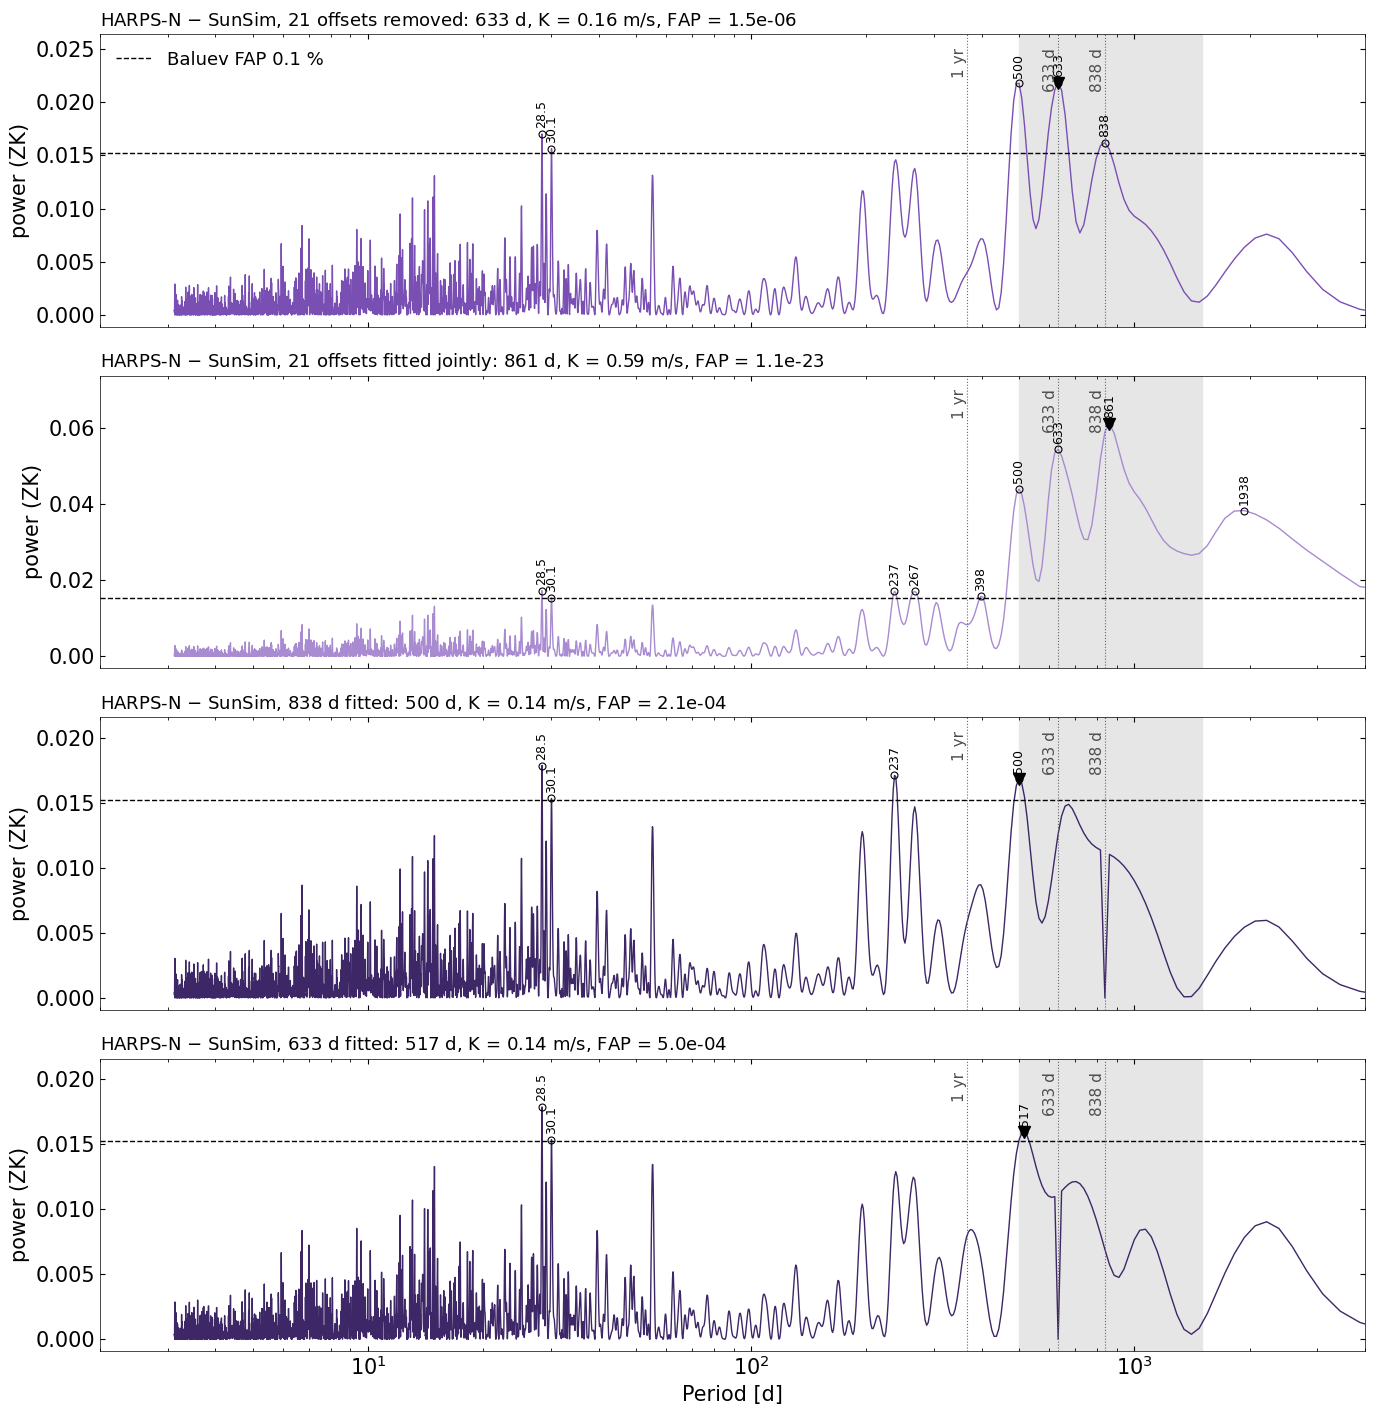

,K at 838 d [m/s],K at 633 d [m/s]
series,,
"HARPS-N, 21 offsets removed",0.141,0.165
"SunSim, 21 offsets removed",0.294,0.270
"HARPS-N - SunSim, 21 offsets removed",0.147,0.163


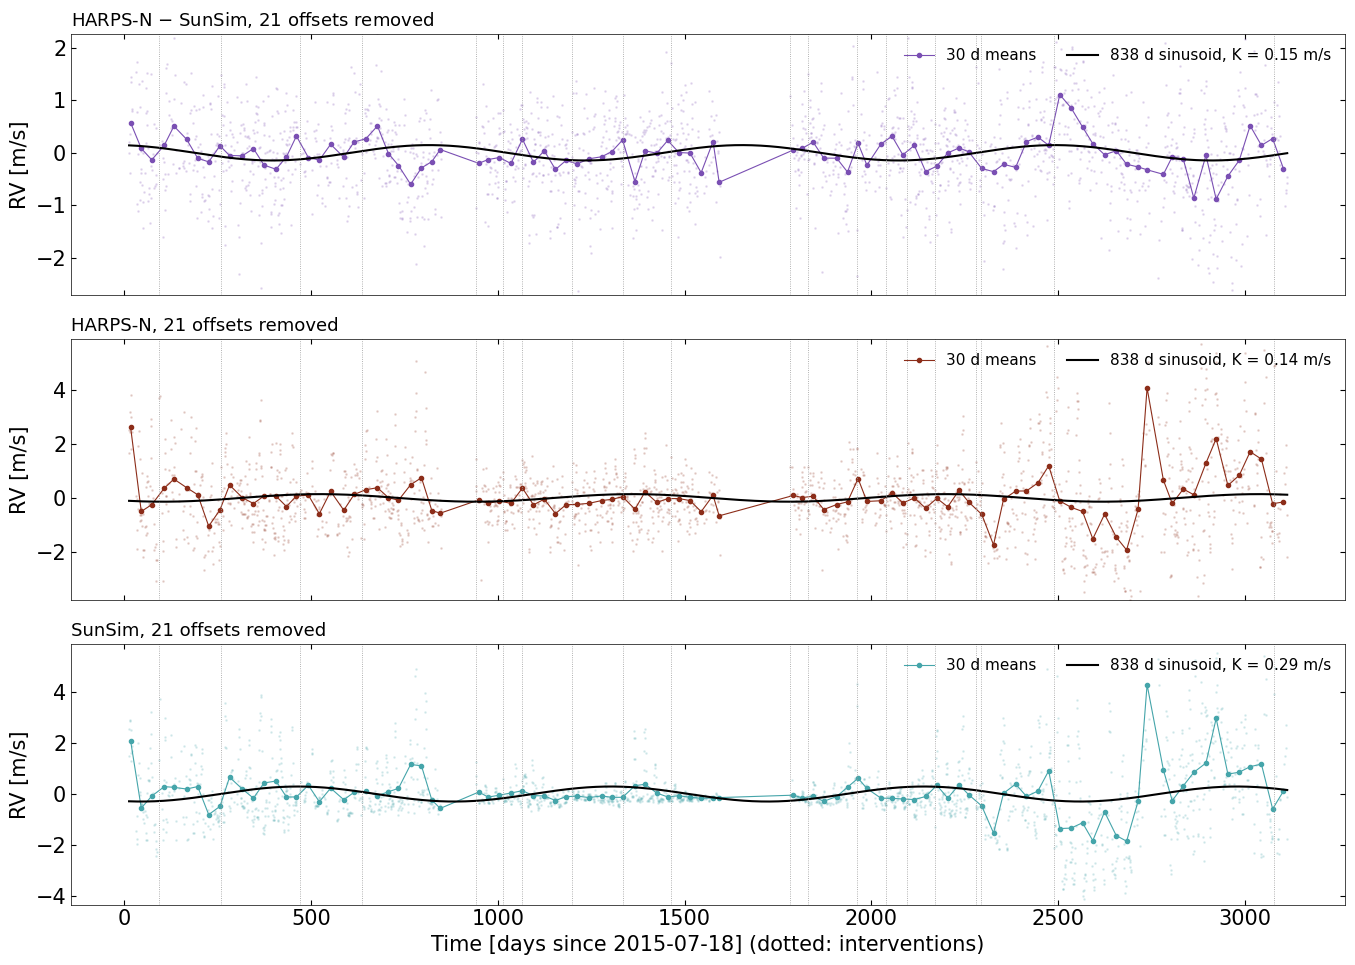

In [56]:
P_860 = peak_in(models['res'], spectra['res'], *P860_RANGE)['P']
P_LONG = peak_in(models['res'], spectra['res'], *LONG)['P']
models['res_860'] = Baluev(T, Y_RES, fixed=(P_860,), name='HARPS-N $-$ SunSim, %.0f d fitted' % P_860)
models['res_long'] = Baluev(T, Y_RES, fixed=(P_LONG,), name='HARPS-N $-$ SunSim, %.0f d fitted' % P_LONG)
for k in ('res_860', 'res_long'):
    spectra[k] = spectrum(models[k])
print('P_860 = %.1f d, P_long = %.1f d; 1/P_long - 1/P_860 = 1/%.0f d (1/T = 1/%.0f d)'
      % (P_860, P_LONG, 1 / (1 / P_LONG - 1 / P_860), models['res'].tbase))
display(peak_table(('res', 'res_joint', 'res_860', 'res_long')))
print('significant peaks (Baluev FAP <= %g) of the residuals:' % FAP)
display(local_peaks(models['res'], spectra['res']))

fig = plot_periodograms([(models[k], spectra[k], c) for k, c in (('res', '#7a4fb3'), ('res_joint', '#a98bd1'),
                                                                ('res_860', '#3d2766'), ('res_long', '#3d2766'))],
                        marks=(('%.0f d' % P_LONG, P_LONG), ('%.0f d' % P_860, P_860)))
save(fig, 'gls_residuals_860')
plt.show()

rows = []
for k in ('obs_off', 'sim_off', 'res'):
    row = {'series': CASES[k][0].replace('$-$', '-')}
    for P in (P_860, P_LONG):
        row['K at %.0f d [m/s]' % P] = sine_fit(T, CASES[k][1], P)[2]
    rows.append(row)
pd.options.display.float_format = '{:.3f}'.format
display(pd.DataFrame(rows).set_index('series'))
pd.options.display.float_format = '{:.3g}'.format

fig = plot_series(('res', 'obs_off', 'sim_off'), ('#7a4fb3', '#8c2d19', '#45a5aa'), P_860)
plt.show()

In [57]:
# where in time: the residuals before CUT_DAY only (the last ~2 years, rising activity of cycle 25, removed)
CUT_DAY = 2400
m = T < CUT_DAY
ra_early = Baluev(T[m], Y_RES[m], name='HARPS-N - SunSim, before %s' % (pd.Timestamp(ORIGIN) + pd.Timedelta(days=CUT_DAY)).date())
sp_early = spectrum(ra_early)
print('%s: %d of %d days' % (ra_early.name, ra_early.N, len(T)))
print('  highest peak: %(P).0f d, K = %(K).2f m/s, FAP %(FAP).1e' % peak_in(ra_early, sp_early))
print('  highest in %d-%d d: %%(P).0f d, K = %%(K).2f m/s, FAP %%(FAP).1e' % LONG % peak_in(ra_early, sp_early, *LONG))
for P in (P_LONG, P_860):
    print('  K of a %.0f d sinusoid: %.2f m/s (all days: %.2f m/s)'
          % (P, sine_fit(T[m], Y_RES[m], P)[2], sine_fit(T, Y_RES, P)[2]))

HARPS-N - SunSim, before 2022-02-11: 1495 of 1984 days
  highest peak: 196 d, K = 0.15 m/s, FAP 3.2e-04
  highest in 500-1500 d: 508 d, K = 0.08 m/s, FAP 1.0e+00
  K of a 633 d sinusoid: 0.06 m/s (all days: 0.16 m/s)
  K of a 838 d sinusoid: 0.01 m/s (all days: 0.15 m/s)


## 3. Injection-recovery on the residuals (offsets already removed), Baluev FAP




In [58]:
RUNS = {'A': models['res'], 'B': models['res_860'], 'C': models['res_long']}
SPEC = {'A': 'res', 'B': 'res_860', 'C': 'res_long'}
P_RES = np.unique(np.concatenate([local_peaks(ra, spectra[SPEC[k]])['P [d]'].to_numpy() for k, ra in RUNS.items() if k in EXCL_RUNS]))
near = (np.abs(P_RES[None, :] - PERIODS_GRID[:, None]) / PERIODS_GRID[:, None] <= EXCL_TOL).any(axis=1)
PERIODS_U = PERIODS_GRID[~near]      # grid without the periods within EXCL_TOL of a significant residual peak
print('residual peaks [d]:', np.round(P_RES, 1))
print('injected periods [d]:', np.round(PERIODS_U, 1))
print('removed [d]:', np.round(PERIODS_GRID[near], 1))
rate, inj = {}, {}
for key, ra in RUNS.items():
    inj[key] = ra.inject(PERIODS_U, AMPLITUDES, n_phases=N_PHASES, fap=FAP, fit=False, before=False, verbose=False)
    rate[key] = ra.detection_rate(period_tol=PERIOD_TOL)
    print('(%s) %-40s power at FAP %g: %.4f' % (key, ra.name.replace('$-$', '-'), FAP, ra.power_level(FAP)))

residual peaks [d]: [ 28.5  30.1 236.7 500.2 516.8 632.9 838.1]
injected periods [d]: [  5.  10.  20.  50. 100. 150. 200. 300. 365. 450. 575.]
removed [d]: []
(A) HARPS-N - SunSim, 21 offsets removed     power at FAP 0.001: 0.0152
(B) HARPS-N - SunSim, 838 d fitted           power at FAP 0.001: 0.0153
(C) HARPS-N - SunSim, 633 d fitted           power at FAP 0.001: 0.0153


## 4. False positives: detections that come from the residuals themselves



In [59]:
fp, flag, highest, noise = {}, {}, {}, {}
for key, ra in RUNS.items():
    sp = spectra[SPEC[key]]
    noise[key] = local_peaks(ra, sp)
    top = peak_in(ra, sp)
    P_noise = noise[key]['P [d]'].to_numpy()
    flag[key] = (np.abs(P_noise[None, :] - PERIODS_U[:, None]) / PERIODS_U[:, None] <= EXCL_TOL).any(axis=1)
    highest[key] = (top['FAP'] <= FAP) & (np.abs(top['P'] - PERIODS_U) / PERIODS_U <= PERIOD_TOL)
    f_noise = 1 / P_noise
    P_inj = PERIODS_U[:, None, None]
    f_rec, df = 1 / inj[key]['P'], 1 / ra.tbase
    det = (inj[key]['fap'] <= FAP) & (np.abs(inj[key]['P'] - P_inj) / P_inj <= PERIOD_TOL)
    from_noise = (np.abs(f_rec[..., None] - f_noise) <= df).any(axis=-1) & (np.abs(f_rec - 1 / P_inj) > df)
    fp[key] = 100 * (det & from_noise).mean(axis=2).T                          # (n_amplitudes, n_periods)
    print('(%s) %s: %d peaks with Baluev FAP <= %g without planet; highest %.1f d (FAP %.1e)'
          % (key, ra.name.replace('$-$', '-'), len(noise[key]), FAP, top['P'], top['FAP']))
    display(noise[key].head(10))

rows = []
for key in RUNS:
    rows.append(pd.Series(['highest' if h else '*' if f else '' for f, h in zip(flag[key], highest[key])],
                          index=PERIODS_U.round(0), name='(%s) significant residual peak within %.0f %%' % (key, 100 * EXCL_TOL)))
    rows.append(pd.Series(fp[key].max(axis=0), index=PERIODS_U.round(0), name='(%s) false positives, max over K [%%]' % key))
    rows.append(pd.Series(fp[key][0], index=PERIODS_U.round(0), name='(%s) false positives at K = %.2f m/s [%%]' % (key, AMPLITUDES[0])))
    rows.append(pd.Series(rate[key][0], index=PERIODS_U.round(0), name='(%s) detected at K = %.2f m/s [%%]' % (key, AMPLITUDES[0])))
pd.options.display.float_format = '{:.1f}'.format
display(pd.DataFrame(rows))
pd.options.display.float_format = '{:.3g}'.format

(A) HARPS-N - SunSim, 21 offsets removed: 5 peaks with Baluev FAP <= 0.001 without planet; highest 632.9 d (FAP 1.5e-06)


,P [d],K [m/s],power,FAP
0,633,0.163,0.0219,1.52e-06
1,500,0.161,0.0218,1.62e-06
2,28.5,0.145,0.017,0.000177
3,838,0.147,0.0162,0.000388
4,30.1,0.141,0.0156,0.000677


(B) HARPS-N - SunSim, 838 d fitted: 4 peaks with Baluev FAP <= 0.001 without planet; highest 28.5 d (FAP 7.7e-05)


,P [d],K [m/s],power,FAP
0,28.5,0.147,0.0179,7.74e-05
1,237,0.145,0.0171,0.000164
2,500,0.142,0.0168,0.000213
3,30.1,0.138,0.0153,0.00092


(C) HARPS-N - SunSim, 633 d fitted: 3 peaks with Baluev FAP <= 0.001 without planet; highest 28.5 d (FAP 7.7e-05)


,P [d],K [m/s],power,FAP
0,28.5,0.147,0.0179,7.72e-05
1,517,0.138,0.016,0.000503
2,30.1,0.138,0.0154,0.000898


,5.0,10.0,20.0,50.0,100.0,150.0,200.0,300.0,365.0,450.0,575.0
(A) significant residual peak within 10 %,,,,,,,,,,,
"(A) false positives, max over K [%]",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
(A) false positives at K = 0.10 m/s [%],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
(A) detected at K = 0.10 m/s [%],0.0,5.0,0.0,0.0,0.0,0.0,41.0,30.0,20.0,53.0,55.0
(B) significant residual peak within 10 %,,,,,,,,,,,
"(B) false positives, max over K [%]",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
(B) false positives at K = 0.10 m/s [%],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
(B) detected at K = 0.10 m/s [%],0.0,33.0,0.0,0.0,0.0,0.0,50.0,33.0,41.0,51.0,54.0
(C) significant residual peak within 10 %,,,,,,,,,,,
"(C) false positives, max over K [%]",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Recovery maps

As cell `[105]` of `10_years_injection.ipynb`: (a) model A, (b) model B; then model C alone. Dashed: 50 % recovered,
solid: 100 % recovered (lower edge of the cells above), blue: M sin i = 1, 2, 3 M⊕. Hatched columns: a significant
peak of the residuals without planet is within 10 % of the injected period (section 4a). If section 4b finds false
positives, a last figure shows the maps without them.

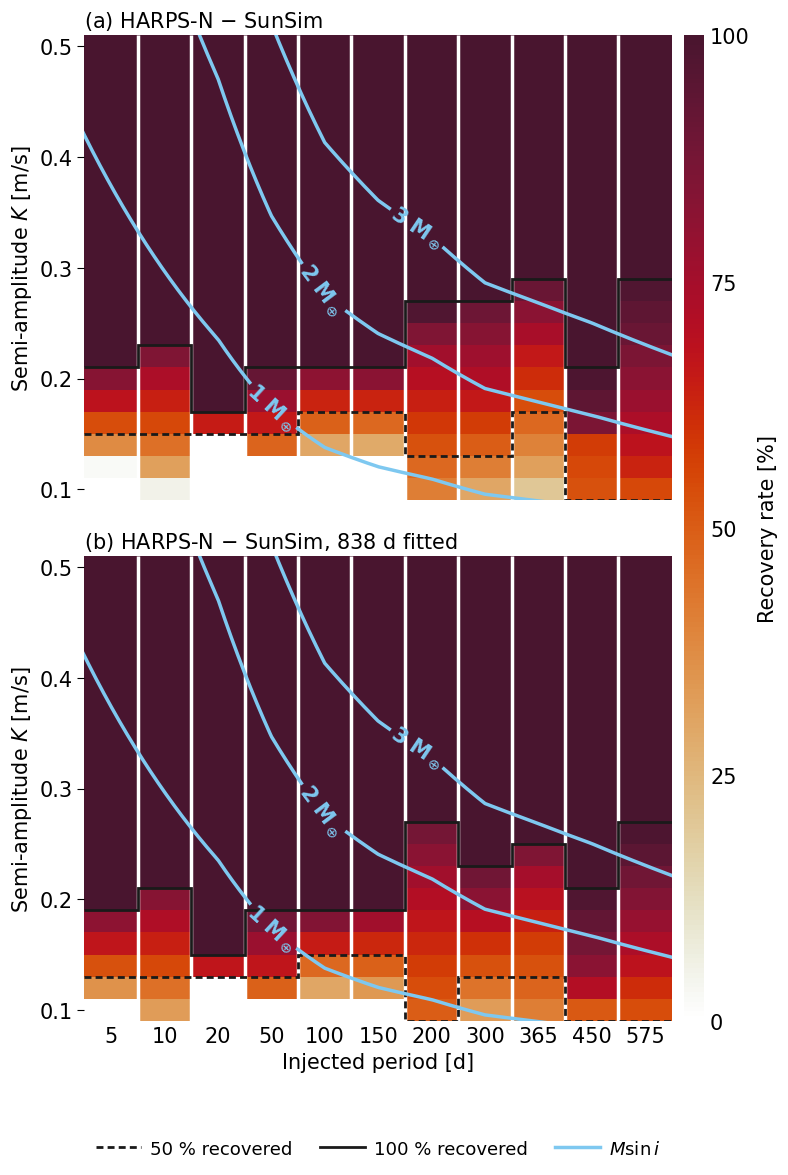

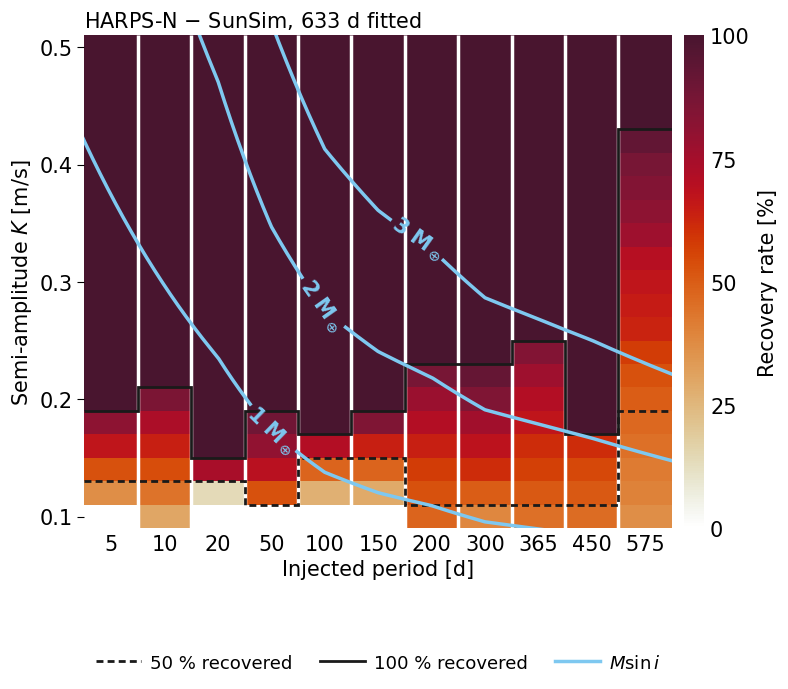

In [60]:
M_EARTH_1YR = (2 * np.pi * 6.674e-11 / (365.25 * 86400)) ** (1 / 3) * 5.972e24 / 1.989e30 ** (2 / 3)   # 0.0895 m/s
CMAP = cmr.get_sub_cmap('cmr.sunburst_r', 0.0, 0.8)                  # light: not recovered, dark red: 100 %
INK = '#1a1a1a'
ACCENT = '#7ec8f0'                                                     # M sin i curves
MASSES = {1: 50, 2: 95, 3: 185}                                         # M sin i [M_Earth]: period of its label
kmass = lambda m, p: m * M_EARTH_1YR * (p / 365.25) ** (-1 / 3)      # K of M sin i = m M_Earth
dk = AMPLITUDES[1] - AMPLITUDES[0]
if P_SCALE == 'list':                # equal-width columns: axis log in P between consecutive injected periods
    _lx, _ix = np.log(PERIODS_U), np.arange(len(PERIODS_U), dtype=float)
    LX = np.r_[-30, _lx, 30]
    IX = np.r_[_ix[0] - (_lx[0] + 30) / (_lx[1] - _lx[0]), _ix, _ix[-1] + (30 - _lx[-1]) / (_lx[-1] - _lx[-2])]
    fwd = lambda p: np.interp(np.log(np.clip(p, 1e-12, None)), LX, IX)
    inv = lambda x: np.exp(np.interp(x, IX, LX))
    X_SCALE = ('function', {'functions': (fwd, inv)})
elif P_SCALE == 'log':
    fwd, inv, X_SCALE = np.log, np.exp, ('log', {})
else:
    fwd, inv, X_SCALE = np.asarray, np.asarray, ('linear', {})
lp = fwd(PERIODS_U)                                                  # columns: injected periods only, edges at midpoints
edges_p = inv(np.r_[1.5 * lp[0] - 0.5 * lp[1], 0.5 * (lp[1:] + lp[:-1]), 1.5 * lp[-1] - 0.5 * lp[-2]])
edges_k = np.append(AMPLITUDES - dk / 2, AMPLITUDES[-1] + dk / 2)
p_fine = np.geomspace(0.1, edges_p[-1] * 1.01, 2000)                       # M sin i curves up to the plot borders


def label_curve(ax, line, x, text, gap=4, **kw):
    # bold text centred on line at x, along its slope; the line is cut under the text
    xd, yd = (np.asarray(v, float) for v in line.get_data())
    y = np.interp(x, xd, yd)
    (x0, y0), (x1, y1) = ax.transData.transform([(xd[i], yd[i]) for i in np.searchsorted(xd, x) + np.array([-3, 3])])
    t = ax.annotate(text, (x, y), ha='center', va='center', color=line.get_color(), fontweight='bold',
                    rotation_mode='anchor', zorder=line.get_zorder() + 1, **kw)
    r = 0.5 * t.get_window_extent(ax.figure.canvas.get_renderer()).width + gap
    t.set_rotation(np.degrees(np.arctan2(y1 - y0, x1 - x0)))
    d = ax.transData.transform(np.c_[xd, yd]) - ax.transData.transform((x, y))
    line.set_ydata(np.where(np.hypot(*d.T) < r, np.nan, yd))


def k_limit(rate, level):
    # lowest K above which every K of the grid reaches level % (NaN: never)
    out = np.full(rate.shape[1], np.nan)
    for j in range(rate.shape[1]):
        bad = np.flatnonzero(rate[:, j] < level)
        if len(bad) == 0:
            out[j] = AMPLITUDES[0]
        elif bad[-1] < len(AMPLITUDES) - 1:
            out[j] = AMPLITUDES[bad[-1] + 1]
    return out


def plot_recovery(panels, name):
    # panels: list of (rate (n_amplitudes, n_periods), title, flagged periods (bool, n_periods))
    with plt.rc_context({'xtick.direction': 'out', 'ytick.direction': 'out', 'xtick.top': False, 'ytick.right': False,
                         'xtick.major.size': 5, 'ytick.major.size': 5, 'axes.linewidth': 0.8}):
        n = len(panels)
        fig = plt.figure(figsize=(8, 6.4 * n))
        gs = fig.add_gridspec(n, 2, width_ratios=[1, 0.035], hspace=0.12, wspace=0.04)
        axes = [fig.add_subplot(gs[0, 0])]
        axes += [fig.add_subplot(gs[i, 0], sharex=axes[0], sharey=axes[0]) for i in range(1, n)]
        cax = fig.add_subplot(gs[:, 1])
        curves = {}
        for ax, (r, title, flagged) in zip(axes, panels):
            im = ax.pcolormesh(edges_p, edges_k, r, cmap=CMAP, vmin=0, vmax=100, rasterized=True)
            ax.vlines(edges_p[1:-1], edges_k[0], edges_k[-1], color='white', lw=2.5, zorder=2)   # column gaps
            for c in np.flatnonzero(flagged):                            # residual peak within 10 % (none here)
                ax.add_patch(plt.Rectangle((edges_p[c], edges_k[0]), edges_p[c + 1] - edges_p[c],
                                           edges_k[-1] - edges_k[0], fill=False, hatch='//', edgecolor='0.35', lw=0,
                                           zorder=3))
            for level, ls in ((50, (0, (2.5, 1.5))), (100, '-')):          # lower edge of the cells above level
                ax.stairs(k_limit(r, level) - dk / 2, edges_p, baseline=None, color=INK, lw=2, ls=ls, zorder=4)
            curves[ax] = {m: ax.plot(p_fine, kmass(m, p_fine), color=ACCENT, lw=2.5, zorder=5)[0] for m in MASSES}
            ax.set_title(title, loc='left', pad=6)
            ax.set_xscale(X_SCALE[0], **X_SCALE[1])
            ax.set_xticks(PERIODS_U, ['%.0f' % p for p in PERIODS_U], rotation=90 if len(PERIODS_U) > 14 else 0, fontsize=12 if len(PERIODS_U) > 14 else None)
            ax.xaxis.set_minor_locator(plt.NullLocator())
            ax.tick_params(axis='x', length=0, pad=4)
            ax.set_ylabel('Semi-amplitude $K$ [m/s]')
            ax.set_ylim(edges_k[0], edges_k[-1])
            ax.set_yticks(np.arange(0.1, 0.51, 0.1))
            for s in ax.spines.values():
                s.set_visible(False)
        axes[0].set_xlim(edges_p[0], edges_p[-1])
        for ax in axes:                                                  # label on every curve, along its slope
            for m, p in MASSES.items():
                label_curve(ax, curves[ax][m], p, '%d M$_\\oplus$' % m, fontsize=15)
        axes[-1].set_xlabel('Injected period [d]')
        for ax in axes[:-1]:
            plt.setp(ax.get_xticklabels(), visible=False)
        cb = fig.colorbar(im, cax=cax, ticks=(0, 25, 50, 75, 100))
        cb.set_label('Recovery rate [%]', labelpad=6)
        cb.outline.set_visible(False)
        cax.tick_params(length=0, pad=4)
        handles = [Line2D([], [], color=INK, ls=(0, (2.5, 1.5)), lw=2), Line2D([], [], color=INK, lw=2),
                   Line2D([], [], color=ACCENT, lw=2.5)]
        labels = ['50 % recovered', '100 % recovered', '$M \\sin i$']
        if any(f.any() for _, _, f in panels):
            handles.append(Patch(facecolor='none', edgecolor='0.35', hatch='//', lw=0))
            labels.append('residual peak (%.0f %%)' % (100 * EXCL_TOL))
        axes[-1].legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=len(handles),
                       frameon=False, borderaxespad=0, handlelength=2.5, handletextpad=0.5, columnspacing=1.5)
    save(fig, name)
    plt.show()


TITLES = {'A': '(a) HARPS-N $-$ SunSim', 'B': '(b) HARPS-N $-$ SunSim, %.0f d fitted' % P_860,
          'C': 'HARPS-N $-$ SunSim, %.0f d fitted' % P_LONG}
plot_recovery([(rate[k], TITLES[k], flag[k]) for k in 'AB'], 'inj_baluev')
plot_recovery([(rate['C'], TITLES['C'], flag['C'])], 'inj_baluev_%.0f' % P_LONG)
if any(fp[k].any() for k in RUNS):
    plot_recovery([(rate[k] - fp[k], TITLES[k] + ', no false pos.', flag[k]) for k in 'AB'], 'inj_baluev_no_fp')

In [61]:
# K [m/s] reached at 50 % and 100 % (lowest K of the grid above which every K reaches the level), with and without
# the false positives of 4b, and M sin i at 1 yr; columns marked * in section 4a are not usable
i1 = int(np.argmin(np.abs(PERIODS_U - YEAR)))
rows = []
for key in RUNS:
    for what, r in (('all detections', rate[key]), ('false positives removed', rate[key] - fp[key])):
        for level in (50, 100):
            lim = np.where(flag[key], np.nan, k_limit(r, level))
            rows.append(pd.Series(lim, index=PERIODS_U.round(0), name='(%s) %s, %d %%' % (key, what, level)))
            print('(%s) %-24s %3d %%: K at %.0f d = %.2f m/s = %.1f M_Earth'
                  % (key, what, level, PERIODS_U[i1], lim[i1], lim[i1] / kmass(1, PERIODS_U[i1])))
pd.options.display.float_format = '{:.2f}'.format
display(pd.DataFrame(rows))
pd.options.display.float_format = '{:.3g}'.format

(A) all detections            50 %: K at 365 d = 0.18 m/s = 2.0 M_Earth
(A) all detections           100 %: K at 365 d = 0.30 m/s = 3.4 M_Earth
(A) false positives removed   50 %: K at 365 d = 0.18 m/s = 2.0 M_Earth
(A) false positives removed  100 %: K at 365 d = 0.30 m/s = 3.4 M_Earth
(B) all detections            50 %: K at 365 d = 0.14 m/s = 1.6 M_Earth
(B) all detections           100 %: K at 365 d = 0.26 m/s = 2.9 M_Earth
(B) false positives removed   50 %: K at 365 d = 0.14 m/s = 1.6 M_Earth
(B) false positives removed  100 %: K at 365 d = 0.26 m/s = 2.9 M_Earth
(C) all detections            50 %: K at 365 d = 0.12 m/s = 1.3 M_Earth
(C) all detections           100 %: K at 365 d = 0.26 m/s = 2.9 M_Earth
(C) false positives removed   50 %: K at 365 d = 0.12 m/s = 1.3 M_Earth
(C) false positives removed  100 %: K at 365 d = 0.26 m/s = 2.9 M_Earth


,5.00,10.00,20.00,50.00,100.00,150.00,200.00,300.00,365.00,450.00,575.00
"(A) all detections, 50 %",0.16,0.16,0.16,0.16,0.18,0.18,0.14,0.14,0.18,0.10,0.10
"(A) all detections, 100 %",0.22,0.24,0.18,0.22,0.22,0.22,0.28,0.28,0.30,0.22,0.30
"(A) false positives removed, 50 %",0.16,0.16,0.16,0.16,0.18,0.18,0.14,0.14,0.18,0.10,0.10
"(A) false positives removed, 100 %",0.22,0.24,0.18,0.22,0.22,0.22,0.28,0.28,0.30,0.22,0.30
"(B) all detections, 50 %",0.14,0.14,0.14,0.14,0.16,0.16,0.10,0.14,0.14,0.10,0.10
"(B) all detections, 100 %",0.20,0.22,0.16,0.20,0.20,0.20,0.28,0.24,0.26,0.22,0.28
"(B) false positives removed, 50 %",0.14,0.14,0.14,0.14,0.16,0.16,0.10,0.14,0.14,0.10,0.10
"(B) false positives removed, 100 %",0.20,0.22,0.16,0.20,0.20,0.20,0.28,0.24,0.26,0.22,0.28
"(C) all detections, 50 %",0.14,0.14,0.14,0.12,0.16,0.16,0.12,0.12,0.12,0.12,0.20
"(C) all detections, 100 %",0.20,0.22,0.16,0.20,0.18,0.20,0.24,0.24,0.26,0.18,0.44
